# 8.2.3 - Model: KNN Light (Lancaster stemmed variant)

**Finding and training a "light" variant of the KNN (K-Nearest Neighbors) classifier - with a significantly smaller .joblib file, while the F1 score is not only close to the heavy version, but in this case is actually better.**

## Motivation

In `8.1.3`, the SVD component-count diagnostics tested values from 500 upward, based on a reasonable assumption: more components = more retained information (explained variance) = better F1.

Based on this, the largest number of components that was feasible with the available computing resources was selected (`N_COMPONENTS=5000`), which resulted in a **1.5GB** model (F1 = 0.8118).

That assumption holds for explained variance, but - as will be shown in this notebook - it does not hold for F1.

`TruncatedSVD` sorts components exclusively by how much variance they explain, not by how relevant they are to sentiment.

For a balanced movie-review corpus, the first ten to twenty components probably already predominantly capture the positive/negative axis - the largest source of lexical difference.

Components after that mostly carry variance related to the movie's topic/genre/plot - noise for sentiment.

For cosine-based KNN, adding these "noisy" dimensions dilutes the similarity between reviews and brings back the same problem (curse of dimensionality) that SVD was supposed to solve, just at another level.

## Why KNN is a specific case

KNN is a lazy model - it does not learn parameters, but stores the entire (reduced) train matrix and searches for neighbors within it. This means that the `.joblib` file size is determined almost exclusively by two things:
- the number of SVD components (`n_components`) - directly determines the number of columns in the matrix stored by the model
- the precision of the numbers used to store that matrix (float64 vs float32 vs float16)

`TruncatedSVD`/`KNeighborsClassifier` store data as `float64` by default.

By switching to `float32` or `float16` (`.astype(np.float32)`), we expect the file size to be halved, but we must examine the impact on model quality and the change in F1.

<br>

<br>

## Theoretical foundation

K-Nearest Neighbors is a lazy model

It does not learn an explicit decision boundary during training (unlike Logistic Regression or trees), but simply memorizes the entire train set.

For a new (test) review, it finds the `k` most similar reviews from the train set (according to some distance/similarity measure) and predicts the majority class among them.

## Why dimensionality reduction is needed - "curse of dimensionality"

The vocabulary contains 68.378 terms - too many for direct application of KNN.

In very high-dimensional spaces, the concept of "closeness" loses meaning.

The distances between "near" and "far" points become increasingly similar as the number of dimensions grows (known as the "curse of dimensionality").

KNN is particularly sensitive to high dimensionality because its decisions are directly based on the distance relationships between samples.

Therefore, a high-dimensional space can make it difficult to distinguish between near and far samples (the other models used can work directly with sparse TF-IDF representations without prior dimensionality reduction).

<br>

Why didn't we solve this already in `3_vectorization.ipynb`, for all models at once:
- A bad decision for the remaining 5 models
- Logistic Regression and SVM (linear models) work well, often better, directly in the sparse high-dimensional space
- If we had compressed everything in advance into a certain number of SVD components:
   - We would lose direct (term-level) interpretability for all models (in `5.x` displaying concrete terms(`not disappoint`, `not recommend`...))
   - We would harm models for which compression is not even necessary
- Where necessary, we solve the problem locally, in the notebook of the model that actually needs it.

## Why `TruncatedSVD`, not `PCA`

`PCA`:
- Requires centering the data (subtracting the mean) before transformation 
- Would convert the sparse TF-IDF matrix into a dense matrix, losing the memory savings that we carefully preserved from `3_vectorization.ipynb` onward

`TruncatedSVD`:
- Works directly on sparse matrices, without centering
- Mathematically close to PCA for our purposes, but more practical for this type of data.

## Processing flow:

1. Load the previously prepared Lancaster stemmed TF-IDF data using the `load_variant()` function

2. Diagnostics and visualization of explained variance on a scale up to 500

3. Check how float32 vs. float64 affects F1 and file size

4. Coarse search - examine a wide range of hyperparameters to get a rough picture of the relationship between F1 and file size

5. Fine search - examine in greater detail the range of hyperparameters that gave the best results in the coarse search

6. Display and select the final combination of hyperparameters for which we obtained the best F1-to-file-size ratio

7. Call the shared `train_and_evaluate()` function for the predetermined hyperparameters


In [1]:
import sys
sys.path.append("..")

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

TMP_MODEL_PATH = Path("../models/_tmp_lite_search.joblib")
MODELS_DIR = Path("../models")

## Data loading

We load the stemmed variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("lancaster")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 68378)
Test:  (9917, 68378)


## Diagnostics and visualization: explained variance on a smaller scale

`n_components` determines how many new dimensions SVD should compress all the original features into.

In `8.1.x`, explained variance was examined for `n_components` from 500 to 5000, and the conclusion was that the curve continues to rise without a clear point of slowdown - hence the decision to go with the largest practical value (5000).

Since the light search targets a significantly smaller number of components, we repeat the same diagnostics over the range 0-500, to see whether there is anything visible there that could indicate a good region in advance.


Cumulative explained variance:
    50 components: 4.5%
   100 components: 7.0%
   150 components: 9.0%
   200 components: 10.7%
   250 components: 12.3%
   300 components: 13.8%
   350 components: 15.2%
   400 components: 16.4%
   450 components: 17.6%
   500 components: 18.7%


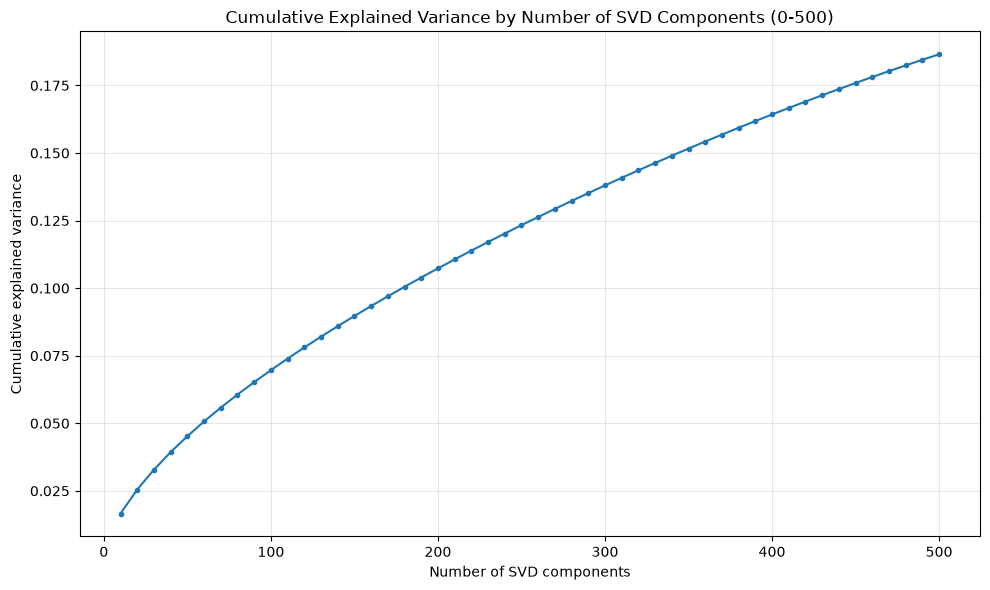

In [3]:
# Vrednosti cumulative explained variance
svd_diagnostic = TruncatedSVD(n_components=500, random_state=1)
svd_diagnostic.fit(X_train)

cumulative_variance = np.cumsum(svd_diagnostic.explained_variance_ratio_)

print("Cumulative explained variance:")
for n in range(50, 501, 50):
    print(f"  {n:4d} components: {cumulative_variance[n - 1]:.1%}")


# Vizualizacija cumulative explained variance
components = list(range(10, 501, 10))

variance = cumulative_variance[np.array(components) - 1]

plt.figure(figsize=(10, 6))
plt.plot(
    components,
    variance,
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.xlabel("Number of SVD components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance by Number of SVD Components (0-500)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Comment - diagnostics

The curve rises smoothly and monotonically even at this much smaller scale - there is no point that would visually indicate that any particular region is especially interesting to examine.

This confirms that the problem with the heavy diagnostics was not that they did not look low enough, but rather the underlying premise itself: the explained variance curve contains no information about where the F1 optimum is - this simply cannot be seen from it, regardless of the range we examine.

We reach the actual optimum (which we will find below) exclusively by measuring F1 directly, not indirectly through variance.


## Check: float16 vs. float32 vs. float64

We check how switching from `float64` to `float32` and then to `float16` affects model accuracy and file size.


In [4]:
# Snima model privremeno na disk i vraća veličinu fajla u MB
def size_of(model):
    joblib.dump(model, TMP_MODEL_PATH)
    size_mb = TMP_MODEL_PATH.stat().st_size / (1024 ** 2)
    TMP_MODEL_PATH.unlink()                                 # brišemo privremeni fajl
    return size_mb

for n_components in [10, 100, 300]:
    svd = TruncatedSVD(n_components=n_components, random_state=1)
    X_reduced = svd.fit_transform(X_train)

    X_64 = X_reduced.astype(np.float64)
    model_64 = KNeighborsClassifier(n_neighbors=50, weights="distance", metric="cosine")
    f1_64 = cross_val_score(model_64, X_64, y_train, cv=3, scoring="f1", n_jobs=-1).mean()
    model_64.fit(X_64, y_train)
    size_64 = size_of(model_64)

    X_32 = X_reduced.astype(np.float32)
    model_32 = KNeighborsClassifier(n_neighbors=50, weights="distance", metric="cosine")
    f1_32 = cross_val_score(model_32, X_32, y_train, cv=3, scoring="f1", n_jobs=-1).mean()
    model_32.fit(X_32, y_train)
    size_32 = size_of(model_32)

    X_16 = X_reduced.astype(np.float16)
    model_16 = KNeighborsClassifier(n_neighbors=50, weights="distance", metric="cosine")
    f1_16 = cross_val_score(model_16, X_16, y_train, cv=3, scoring="f1", n_jobs=-1).mean()
    model_16.fit(X_16, y_train)
    size_16 = size_of(model_16)

    print(f"n_components={n_components}")
    print(f"  float64: F1={f1_64:.4f}  size={size_64:.2f}MB")
    print(f"  float32: F1={f1_32:.4f}  size={size_32:.2f}MB")
    print(f"  float16: F1={f1_16:.4f}  size={size_16:.2f}MB")

n_components=10
  float64: F1=0.8137  size=3.33MB
  float32: F1=0.8137  size=1.82MB
  float16: F1=0.8136  size=1.06MB
n_components=100
  float64: F1=0.8055  size=30.57MB
  float32: F1=0.8055  size=15.43MB
  float16: F1=0.8055  size=7.87MB
n_components=300
  float64: F1=0.8024  size=91.09MB
  float32: F1=0.8024  size=45.70MB
  float16: F1=0.8024  size=23.00MB


## Comment - float16 vs. float32 vs. float64

F1 is identical across all 3 variants (the difference in number precision does not affect cosine similarity), while the size is drastically reduced.

This confirms the decision to use `float16` throughout the rest of the search - a free halving of the size, with no impact whatsoever on model quality.

`float64` has a precision of about 15–16 significant decimal digits, while `float16` preserves about 3–4 significant digits. For our purposes, this precision is obviously more than sufficient, since despite the large reduction in precision, we get the same F1 result.


## Helper function for measuring F1 and file size

Similar principle as in `7.2.x` (Random Forest light) - for each combination:

1. Parameters:
    - `X_reduced` (already reduced, `float16` matrix) and `n_components` are passed as the ready result of the `TruncatedSVD` transformation, performed once per `n_components` value at the call site (in the coarse/fine loops) - not inside the function itself.
    - `TruncatedSVD` fitting is the most expensive part of the entire search, while changing `n_neighbors`/`weights`/`metric` does not require re-transforming the data, only a new KNN model on the same, already reduced data.
    - If the transformation were instead performed inside `evaluate_combo`, the same (expensive) SVD fit would be unnecessarily repeated for every `n_neighbors`/`weights`/`metric` combination, instead of only once per `n_components`.

2. We estimate F1 using 3-fold cross-validation on the TRAIN set (`cross_val_score`) - the same number of folds that `8.1.x` used during the component-number selection phase, for speed and comparability with the heavy diagnostics

3. We train the model on the entire TRAIN set (the same thing that happens in the final step) and temporarily save it to disk to measure the actual size of the `.joblib` file - for KNN, the size depends on the number of training examples, number of components, and number precision, so measuring the actual saved file is the most reliable approach instead of calculating it in advance

4. We delete the temporary file after measurement (we don't clutter the `models/` folder with intermediate results)

The TEST set is not used at all during this research phase - it is reserved for the final evaluation of the selected model, following the same principle used by `train_and_evaluate()`.

`evaluate_combo` - for a given combination of hyperparameters, returns the estimated CV F1 and the size (in MB) of the resulting `.joblib` file trained on the entire TRAIN set.


In [5]:
def evaluate_combo(X_reduced, n_components, n_neighbors, weights, metric, explained_variance):
    model = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric)

    start = time.time()

    # CV F1 procena (bez čuvanja modela) kao srednja vrednost od 3-fold cross-validation
    cv_f1 = cross_val_score(model, X_reduced, y_train, cv=3, scoring="f1", n_jobs=-1).mean()

    # Trening na celom TRAIN skupu, radi merenja stvarne veličine fajla
    model.fit(X_reduced, y_train)
    size_mb = size_of(model)                # funkcija definisana u proveri za float, vraća veličinu modela u MB

    elapsed = time.time() - start

    return {
        "n_components": n_components,
        "n_neighbors": n_neighbors,
        "weights": weights,
        "metric": metric,
        "f1": cv_f1,
        "size_mb": size_mb,
        "explained_variance": explained_variance,
        "time_s": elapsed,
    }

## Step 1: Coarse search

We examine a wide range of `n_components`, `n_neighbors`, `weights`, and `metric`

We get a rough picture of the relationship between F1 and file size before focusing on a narrower region.


In [6]:
coarse_n_components = [10, 50, 200, 500]
coarse_n_neighbors = [10, 100, 300]
coarse_weights = ["uniform", "distance"]
coarse_metric = ["cosine", "euclidean"]

coarse_results = []
for n_components in coarse_n_components:
    svd = TruncatedSVD(n_components=n_components, random_state=1)   # SVD za redukciju dimenzionalnosti računamo jednom ovde
    X_reduced = svd.fit_transform(X_train).astype(np.float16)
    explained_variance = svd.explained_variance_ratio_.sum()

    for n_neighbors in coarse_n_neighbors:
        for weights in coarse_weights:
            for metric in coarse_metric:
                result = evaluate_combo(X_reduced, n_components, n_neighbors, weights, metric, explained_variance)
                coarse_results.append(result)

coarse_df = pd.DataFrame(coarse_results)

coarse_df.style.format({"f1": "{:.4f}", "size_mb": "{:.1f}", "explained_variance": "{:.1%}",  "time_s": "{:.0f}"})

,n_components,n_neighbors,weights,metric,f1,size_mb,explained_variance,time_s
0,10,10,uniform,cosine,0.7914,1.1,1.7%,9
1,10,10,uniform,euclidean,0.7851,4.8,1.7%,4
2,10,10,distance,cosine,0.7996,1.1,1.7%,9
3,10,10,distance,euclidean,0.7970,4.8,1.7%,4
4,10,100,uniform,cosine,0.8121,1.1,1.7%,9
5,10,100,uniform,euclidean,0.8098,4.8,1.7%,7
6,10,100,distance,cosine,0.8137,1.1,1.7%,9
7,10,100,distance,euclidean,0.8116,4.8,1.7%,6
8,10,300,uniform,cosine,0.8087,1.1,1.7%,9
9,10,300,uniform,euclidean,0.8082,4.8,1.7%,9


## Comment on the coarse search

The result is contrary to the intuition from `8.1.x`:
- F1 **decreases** as `n_components` increases - exactly the opposite of what we would expect based on explained variance, which increases monotonically all the way to 5000 components in `8.1.x`
- Even the smallest tested value (`n_components=10`) gives an F1 better than the entire heavy version with 5000 components (0.8118), with a file on the order of a few MB versus 1.5GB

Based on the coarse search:
- `n_components` is the only real "driver" of file size - since we have fixed the precision at `float16`, the size depends exclusively on the number of components
- The optimal `n_neighbors` is not the same for all `n_components` values - fewer components go with a larger number of neighbors
- `weights` has a clear winner, which is `"distance"`; in the fine search, we will fix it to this value
- `metric` has a clear winner, which is `"cosine"`; in the fine search, we will fix it to this value

No combination in this step reveals where the actual peak is - we only have rough confirmation that it is somewhere below `n_components=50`.

We move on to a fine search in the `n_components` 0-50 region, with a denser step for both `n_components` and `n_neighbors`.


## Step 2: Fine search around the target values

We zoom in on `n_components` between 5 and 45

We examine `n_neighbors` in detail in the range from 10 to 150


In [7]:
fine_n_components = [5, 10, 15, 20, 25, 30, 35, 40, 45]
fine_n_neighbors = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150]
fine_weights = "distance"
fine_metric = "cosine"

fine_results = []
for n_components in fine_n_components:
    svd = TruncatedSVD(n_components=n_components, random_state=1)   # SVD za redukciju dimenzionalnosti računamo jednom ovde
    X_reduced = svd.fit_transform(X_train).astype(np.float16)
    explained_variance = svd.explained_variance_ratio_.sum()
    
    for n_neighbors in fine_n_neighbors:
        result = evaluate_combo(X_reduced, n_components, n_neighbors, fine_weights, fine_metric, explained_variance)
        fine_results.append(result)

fine_df = pd.DataFrame(fine_results)
all_results_df = pd.concat([coarse_df, fine_df], ignore_index=True)

## Pareto analysis: selecting the final combination

From all tested combinations (coarse + fine), we select those that are Pareto-optimal around the target size.

In other words, there is no other combination that is simultaneously smaller and better than them.


In [8]:
sorted_df = all_results_df.sort_values("size_mb").reset_index(drop=True)

pareto_rows = []
best_f1_so_far = -np.inf

for _, row in sorted_df.iterrows():
    if row["f1"] > best_f1_so_far:
        pareto_rows.append(row)
        best_f1_so_far = row["f1"]

pareto_df = pd.DataFrame(pareto_rows).reset_index(drop=True)

pareto_df[["n_components", "n_neighbors", "f1", "size_mb"]].style.format({"n_components": "{:.0f}", "n_neighbors": "{:.0f}", "f1": "{:.4f}", "size_mb": "{:.1f}"})

,n_components,n_neighbors,f1,size_mb
0,5,90,0.7903,0.7
1,5,130,0.7920,0.7
2,5,120,0.7921,0.7
3,5,150,0.7921,0.7
4,5,140,0.7923,0.7
5,10,100,0.8121,1.1
6,10,100,0.8137,1.1
7,10,80,0.8139,1.1
8,10,70,0.8140,1.1
9,15,20,0.8176,1.4


## Visual Reprezentation

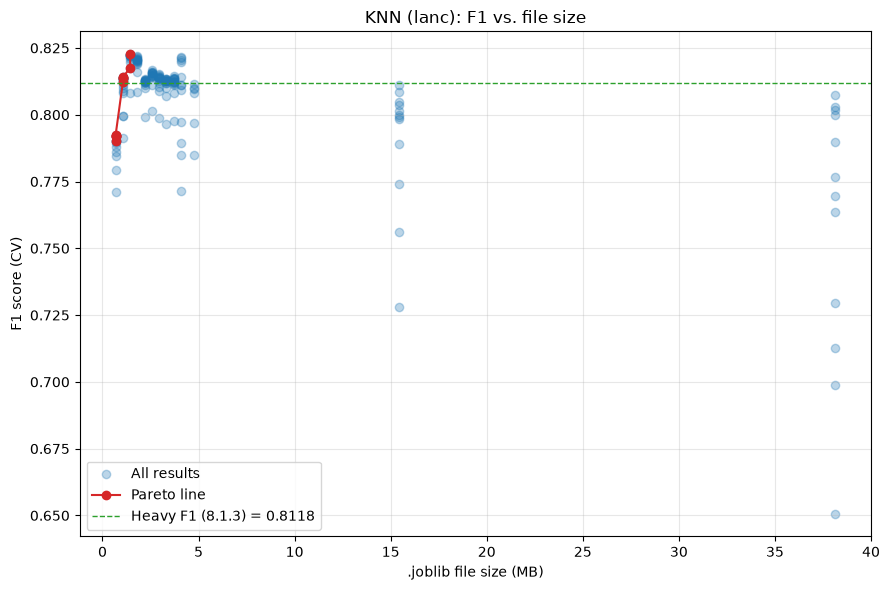

In [9]:
plt.figure(figsize=(9, 6))
plt.scatter(all_results_df["size_mb"], all_results_df["f1"], alpha=0.3, label="All results")
plt.plot(pareto_df["size_mb"], pareto_df["f1"], marker="o", color="tab:red", label="Pareto line")

plt.axhline(0.8118, color="tab:green", linestyle="--", linewidth=1, label="Heavy F1 (8.1.3) = 0.8118")

plt.xlabel(".joblib file size (MB)")
plt.ylabel("F1 score (CV)")
plt.title("KNN (lanc): F1 vs. file size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final combination selection

We choose `n_components=15, n_neighbors=120, weights='distance', metric='cosine'`:

- Within `n_components=15`, `n_neighbors=120` gives the best F1 (0.8226) among all tested neighbor values for that number of components

- The same `n_components` as in the `stem` and `lem` variants (15) - confirming that the 10-15 component range is consistently the best across all four preprocessing variants

- Compared to the heavy version (`8.1.3`: F1=0.8118, size-1.5GB, `n_components=5000`, 57.8% retained variance), the light combination is both smaller and better in terms of F1 (0.8226 CV vs. 0.8118)

- In the Pareto table, there are two rows with identical `n_components=10, n_neighbors=100`, but different F1 values (0.8121 and 0.8137). This is not a code error; it happens because one value remained from the coarse search with the parameters: `weights='uniform', metric='cosine'`

Additionally, in `/models` we also save `svd_reducer_lite_knn_lanc.joblib`, so that later we can apply the identical dimensionality reduction to the TF-IDF representation of new, unseen reviews (e.g. in `predict_review.py`), without needing to fit `TruncatedSVD` again on the train set.

Note:
- The F1 above is an estimate obtained through cross-validation on the TRAIN set
- The final evaluation on the TEST set, which we have not used so far, is obtained only now, through `train_and_evaluate()` from `src/modeling.py`


Saved: ..\models\svd_reducer_lite_knn_lanc.joblib

Best n_components: 15
========== lite_knn (lanc) ==========
Best parameters: {'metric': 'cosine', 'n_neighbors': 120, 'weights': 'distance'}
GridSearchCV time: 12.2s

Accuracy  : 0.8220
Precision : 0.8160
Recall    : 0.8332
F1        : 0.8245


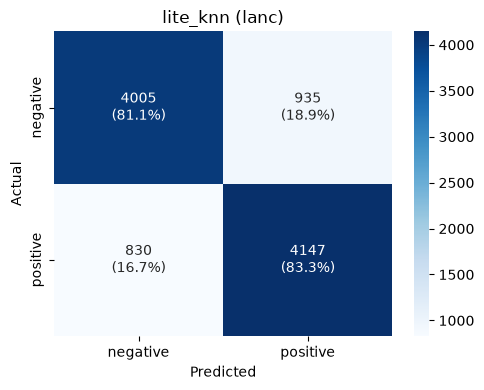


Saved:
  ..\models\lite_knn_lanc.joblib
  ..\results\metrics\lite_knn_lanc.json
  ..\results\figures\lite_knn_lanc_confusion_matrix.png


In [3]:
best_n_components = 15

svd = TruncatedSVD(n_components=best_n_components, random_state=1)
X_train_reduced = svd.fit_transform(X_train).astype(np.float16)
X_test_reduced = svd.transform(X_test).astype(np.float16)

joblib.dump(svd, MODELS_DIR / "svd_reducer_lite_knn_lanc.joblib")
print(f"Saved: {MODELS_DIR / 'svd_reducer_lite_knn_lanc.joblib'}")
print()

print(f"Best n_components: {best_n_components}")

model = KNeighborsClassifier()

param_grid = {
    "n_neighbors": [120],
    "weights": ["distance"],
    "metric": ["cosine"],
}

metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train_reduced,
    y_train=y_train,
    X_test=X_test_reduced,
    y_test=y_test,
    model_name="lite_knn",
    variant="lanc",
)

## Conclusions

- Instead of the standard approach from `8.1.3` (choosing `n_components` based on explained variance, then using GridSearchCV only over KNN hyperparameters), the light version was explored through a targeted search that directly measures F1 and `.joblib` file size for each `n_components` × `n_neighbors` combination - coarse search followed by fine search, then Pareto analysis

- Key finding: F1 **does not** increase monotonically with the number of SVD components, even though explained variance increases monotonically both in this much smaller range (0-500) and, just as in `8.1.x`, across the range up to 5000. F1 reaches its peak around `n_components=15` (0.8245), then decreases - `TruncatedSVD` sorts components by explained variance, not by relevance to sentiment, so components after the peak mostly introduce noise (likely related to the movie's topic/genre), which dilutes the similarity between reviews for cosine-based KNN

- The number precision check (`float64` vs. `float32` vs. `float16`) showed identical F1 across all three variants at all three tested `n_components` values (10, 100, 300), while file size decreases almost linearly with precision (e.g. at `n_components=100`: 30.57MB → 15.43MB → 7.87MB) - `float16` was adopted for the entire subsequent search and the final model, with no measurable impact on quality

- Selected final combination: `n_components=15, n_neighbors=120, weights='distance', metric='cosine'` - `weights`/`metric` are identical to the heavy configuration

- Final results on the TEST set (`lite_knn`, lanc):
    - Accuracy  : 0.8220
    - Precision : 0.8160
    - Recall    : 0.8332
    - F1        : 0.8245
    - Saved file size: ~1.4 MB

- Test F1 (0.8245) is higher than the CV estimate from the search (0.8226, difference +0.0019) - the cross-validation estimate was not optimistically biased

- Compared to the heavy version (`8.1.3`: F1=0.8118, size≈1.5GB), the light version does not lose F1; instead, it increases it by 0.0127 (~1.56%), with a file that is over 1000x smaller

- Recall (0.8332) is higher than precision (0.8160) for the light version - the same pattern as in the previous variants

- Overall conclusion: The KNN light result is stronger evidence than any RF light finding that the heavy diagnostics (`8.1.3`) were not merely "over-dimensioned for safety", but were based on a flawed premise (more components = better), which actively hurt F1, not just file size. The lite search solved both problems simultaneously - a smaller file and a better result - which was not the case with any of the Random Forest variants (where light always meant a small but real loss in F1)
